In [4]:
# Cell 1: Import Required Libraries and Configure Environment

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             roc_auc_score, roc_curve, auc, confusion_matrix, classification_report)
import warnings
import time
import os

warnings.filterwarnings('ignore')

# Define specificity_score function
def specificity_score(y_true, y_pred):
    """Calculate specificity (true negative rate)"""
    from sklearn.metrics import confusion_matrix
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
np.random.seed(42)

print("="*100)
print("K-NEAREST NEIGHBORS (kNN) HYPERPARAMETER TUNING - SPLIT DATASETS (TRAIN/VAL/TEST)")
print("="*100)
print("\n✓ All libraries imported successfully")
print(f"  - pandas: {pd.__version__}")
print(f"  - numpy: {np.__version__}")
print(f"  - scikit-learn: imported successfully")
print("\n✓ Visualization style configured")
print("✓ Random seed fixed at 42 for reproducibility")

K-NEAREST NEIGHBORS (kNN) HYPERPARAMETER TUNING - SPLIT DATASETS (TRAIN/VAL/TEST)

✓ All libraries imported successfully
  - pandas: 2.3.3
  - numpy: 2.2.6
  - scikit-learn: imported successfully

✓ Visualization style configured
✓ Random seed fixed at 42 for reproducibility


In [5]:
# Cell 2: Load Split Datasets (Train/Validation/Test)

print("\n" + "="*100)
print("LOADING SPLIT DATASETS (TRAIN/VALIDATION/TEST)")
print("="*100)

# Load split datasets
df_train = pd.read_csv('final_ml_dataset_train.csv')
df_val = pd.read_csv('final_ml_dataset_validation.csv')
df_test = pd.read_csv('final_ml_dataset_test.csv')

print(f"\n✓ Loaded final_ml_dataset_train.csv: {df_train.shape}")
print(f"✓ Loaded final_ml_dataset_validation.csv: {df_val.shape}")
print(f"✓ Loaded final_ml_dataset_test.csv: {df_test.shape}")

# Extract target variables
y_train = df_train['Activity'].values
y_val = df_val['Activity'].values
y_test = df_test['Activity'].values

print(f"\n{'Data Split Summary':^100}")
print(f"{'-'*100}")
print(f"Training set:   {len(y_train):4d} samples (Active: {np.sum(y_train):3d}, Inactive: {len(y_train)-np.sum(y_train):3d})")
print(f"Validation set: {len(y_val):4d} samples (Active: {np.sum(y_val):3d}, Inactive: {len(y_val)-np.sum(y_val):3d})")
print(f"Test set:       {len(y_test):4d} samples (Active: {np.sum(y_test):3d}, Inactive: {len(y_test)-np.sum(y_test):3d})")
print(f"Total:          {len(y_train) + len(y_val) + len(y_test):4d} samples")


LOADING SPLIT DATASETS (TRAIN/VALIDATION/TEST)

✓ Loaded final_ml_dataset_train.csv: (1188, 4516)
✓ Loaded final_ml_dataset_validation.csv: (255, 4516)
✓ Loaded final_ml_dataset_test.csv: (255, 4516)

                                         Data Split Summary                                         
----------------------------------------------------------------------------------------------------
Training set:   1188 samples (Active: 440, Inactive: 748)
Validation set:  255 samples (Active:  94, Inactive: 161)
Test set:        255 samples (Active:  95, Inactive: 160)
Total:          1698 samples


In [6]:
# Cell 3: Extract Feature Sets from Split Datasets

print("\n" + "="*100)
print("FEATURE SET EXTRACTION FROM SPLIT DATASETS")
print("="*100)

feature_sets = {}

# 1. 217 Descriptors (Pre-scaled with Scaled_ prefix)
descriptor_cols = [col for col in df_train.columns if col.startswith('Scaled_')]
X_train_desc = df_train[descriptor_cols].values
X_val_desc = df_val[descriptor_cols].values
X_test_desc = df_test[descriptor_cols].values
feature_sets['217_Descriptors'] = {
    'train': X_train_desc, 'val': X_val_desc, 'test': X_test_desc,
    'name': '217 Descriptors'
}
print(f"\n✓ 217 Descriptors: {X_train_desc.shape[1]} features")

# 2. MACCS_167 Fingerprints
maccs_cols = [col for col in df_train.columns if col.startswith('MACCS_')]
X_train_maccs = df_train[maccs_cols].values
X_val_maccs = df_val[maccs_cols].values
X_test_maccs = df_test[maccs_cols].values
feature_sets['MACCS_167'] = {
    'train': X_train_maccs, 'val': X_val_maccs, 'test': X_test_maccs,
    'name': 'MACCS_167'
}
print(f"✓ MACCS_167 Fingerprints: {X_train_maccs.shape[1]} features")

# 3. RDKit_2048 Fingerprints
rdkit_cols = [col for col in df_train.columns if col.startswith('RDKit_')]
X_train_rdkit = df_train[rdkit_cols].values
X_val_rdkit = df_val[rdkit_cols].values
X_test_rdkit = df_test[rdkit_cols].values
feature_sets['RDKit_2048'] = {
    'train': X_train_rdkit, 'val': X_val_rdkit, 'test': X_test_rdkit,
    'name': 'RDKit_2048'
}
print(f"✓ RDKit_2048 Fingerprints: {X_train_rdkit.shape[1]} features")

# 4. Morgan_2048 Fingerprints
morgan_cols = [col for col in df_train.columns if col.startswith('Morgan_')]
X_train_morgan = df_train[morgan_cols].values
X_val_morgan = df_val[morgan_cols].values
X_test_morgan = df_test[morgan_cols].values
feature_sets['Morgan_2048'] = {
    'train': X_train_morgan, 'val': X_val_morgan, 'test': X_test_morgan,
    'name': 'Morgan_2048'
}
print(f"✓ Morgan_2048 Fingerprints: {X_train_morgan.shape[1]} features")

print(f"\n{'Feature Set Summary':^100}")
print(f"{'-'*100}")
for name, data in feature_sets.items():
    print(f"{name:20s}: Train {data['train'].shape} | Val {data['val'].shape} | Test {data['test'].shape}")


FEATURE SET EXTRACTION FROM SPLIT DATASETS

✓ 217 Descriptors: 249 features
✓ MACCS_167 Fingerprints: 168 features
✓ RDKit_2048 Fingerprints: 2049 features
✓ Morgan_2048 Fingerprints: 2049 features

                                        Feature Set Summary                                         
----------------------------------------------------------------------------------------------------
217_Descriptors     : Train (1188, 249) | Val (255, 249) | Test (255, 249)
MACCS_167           : Train (1188, 168) | Val (255, 168) | Test (255, 168)
RDKit_2048          : Train (1188, 2049) | Val (255, 2049) | Test (255, 2049)
Morgan_2048         : Train (1188, 2049) | Val (255, 2049) | Test (255, 2049)


In [7]:
# Cell 4: Define kNN Hyperparameter Grid

print("\n" + "="*100)
print("DEFINING kNN HYPERPARAMETER GRID")
print("="*100)

# Define hyperparameter grid for kNN
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19],  # 9 odd values for tie-breaking
    'metric': ['euclidean', 'manhattan', 'minkowski']   # 3 distance metrics
}

n_combinations = len(param_grid['n_neighbors']) * len(param_grid['metric'])
total_fits = n_combinations * 4 * 5  # 4 feature sets × 5-fold CV

print(f"\n{'Hyperparameter Grid Configuration':^100}")
print(f"{'-'*100}")
print(f"n_neighbors (odd values):  {param_grid['n_neighbors']}")
print(f"metric (distance):         {param_grid['metric']}")
print(f"\nTotal combinations:        {n_combinations}")
print(f"Total grid searches (all datasets): {n_combinations * 4}")
print(f"Total model fits (with 5-fold CV): {total_fits}")
print(f"\nCross-Validation:          5-fold StratifiedKFold (training set only)")
print(f"Scoring metric:            ROC-AUC")
print(f"Expected execution time:   ~2-4 minutes (lightweight algorithm)")

# Create stratified k-fold splitter for cross-validation
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


DEFINING kNN HYPERPARAMETER GRID

                                 Hyperparameter Grid Configuration                                  
----------------------------------------------------------------------------------------------------
n_neighbors (odd values):  [3, 5, 7, 9, 11, 13, 15, 17, 19]
metric (distance):         ['euclidean', 'manhattan', 'minkowski']

Total combinations:        27
Total grid searches (all datasets): 108
Total model fits (with 5-fold CV): 540

Cross-Validation:          5-fold StratifiedKFold (training set only)
Scoring metric:            ROC-AUC
Expected execution time:   ~2-4 minutes (lightweight algorithm)


In [8]:
# Cell 5: kNN Hyperparameter Tuning with GridSearchCV

print("\n" + "="*100)
print("kNN HYPERPARAMETER TUNING WITH GRIDSEARCHCV")
print("="*100)

# Store results for all feature sets
knn_results = {}
best_models = {}

feature_set_names = list(feature_sets.keys())

for i, feature_name in enumerate(feature_set_names, 1):
    print(f"\n{'Processing ' + feature_name:^100}")
    print(f"{'-'*100}")
    
    X_train = feature_sets[feature_name]['train']
    y_train_current = y_train
    
    # Initialize kNN model
    knn_model = KNeighborsClassifier()
    
    # Perform GridSearchCV
    grid_search = GridSearchCV(
        estimator=knn_model,
        param_grid=param_grid,
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )
    
    print(f"[{i}/{len(feature_set_names)}] Running GridSearchCV on {feature_name}...")
    grid_search.fit(X_train, y_train_current)
    
    # Store results
    knn_results[feature_name] = {
        'grid_search': grid_search,
        'best_params': grid_search.best_params_,
        'best_score': grid_search.best_score_,
        'cv_results': grid_search.cv_results_
    }
    
    best_models[feature_name] = grid_search.best_estimator_
    
    print(f"✓ Best parameters: {grid_search.best_params_}")
    print(f"✓ Best CV ROC-AUC score: {grid_search.best_score_:.4f}")

print(f"\n{'='*100}")
print("GridSearchCV completed for all feature sets!")


kNN HYPERPARAMETER TUNING WITH GRIDSEARCHCV

                                     Processing 217_Descriptors                                     
----------------------------------------------------------------------------------------------------
[1/4] Running GridSearchCV on 217_Descriptors...
✓ Best parameters: {'metric': 'manhattan', 'n_neighbors': 5}
✓ Best CV ROC-AUC score: 0.8110

                                        Processing MACCS_167                                        
----------------------------------------------------------------------------------------------------
[2/4] Running GridSearchCV on MACCS_167...
✓ Best parameters: {'metric': 'manhattan', 'n_neighbors': 7}
✓ Best CV ROC-AUC score: 0.7686

                                       Processing RDKit_2048                                        
----------------------------------------------------------------------------------------------------
[3/4] Running GridSearchCV on RDKit_2048...
✓ Best parameters: {'met

In [9]:
# Cell 6: Evaluate kNN Models on Train/Validation/Test Sets

print("\n" + "="*100)
print("EVALUATING kNN MODELS ON TRAIN/VALIDATION/TEST SETS")
print("="*100)

evaluation_results = {}

for feature_name in feature_set_names:
    print(f"\n{'Evaluating ' + feature_name:^100}")
    print(f"{'-'*100}")
    
    best_model = best_models[feature_name]
    
    X_train = feature_sets[feature_name]['train']
    X_val = feature_sets[feature_name]['val']
    X_test = feature_sets[feature_name]['test']
    
    # Predictions and probabilities
    y_train_pred = best_model.predict(X_train)
    y_train_proba = best_model.predict_proba(X_train)[:, 1]
    
    y_val_pred = best_model.predict(X_val)
    y_val_proba = best_model.predict_proba(X_val)[:, 1]
    
    y_test_pred = best_model.predict(X_test)
    y_test_proba = best_model.predict_proba(X_test)[:, 1]
    
    # Calculate metrics for each set
    metrics_train = {
        'accuracy': accuracy_score(y_train, y_train_pred),
        'precision': precision_score(y_train, y_train_pred),
        'recall': recall_score(y_train, y_train_pred),
        'f1': f1_score(y_train, y_train_pred),
        'roc_auc': roc_auc_score(y_train, y_train_proba),
        'sensitivity': recall_score(y_train, y_train_pred),
        'specificity': specificity_score(y_train, y_train_pred)
    }
    
    metrics_val = {
        'accuracy': accuracy_score(y_val, y_val_pred),
        'precision': precision_score(y_val, y_val_pred),
        'recall': recall_score(y_val, y_val_pred),
        'f1': f1_score(y_val, y_val_pred),
        'roc_auc': roc_auc_score(y_val, y_val_proba),
        'sensitivity': recall_score(y_val, y_val_pred),
        'specificity': specificity_score(y_val, y_val_pred)
    }
    
    metrics_test = {
        'accuracy': accuracy_score(y_test, y_test_pred),
        'precision': precision_score(y_test, y_test_pred),
        'recall': recall_score(y_test, y_test_pred),
        'f1': f1_score(y_test, y_test_pred),
        'roc_auc': roc_auc_score(y_test, y_test_proba),
        'sensitivity': recall_score(y_test, y_test_pred),
        'specificity': specificity_score(y_test, y_test_pred)
    }
    
    evaluation_results[feature_name] = {
        'train_metrics': metrics_train,
        'val_metrics': metrics_val,
        'test_metrics': metrics_test,
        'train_pred': y_train_pred,
        'val_pred': y_val_pred,
        'test_pred': y_test_pred,
        'test_proba': y_test_proba,
        'test_pred_proba_0': 1 - y_test_proba,
        'test_pred_proba_1': y_test_proba
    }
    
    print(f"✓ Training - Accuracy: {metrics_train['accuracy']:.4f}, ROC-AUC: {metrics_train['roc_auc']:.4f}")
    print(f"✓ Validation - Accuracy: {metrics_val['accuracy']:.4f}, ROC-AUC: {metrics_val['roc_auc']:.4f}")
    print(f"✓ Test - Accuracy: {metrics_test['accuracy']:.4f}, ROC-AUC: {metrics_test['roc_auc']:.4f}")


EVALUATING kNN MODELS ON TRAIN/VALIDATION/TEST SETS

                                     Evaluating 217_Descriptors                                     
----------------------------------------------------------------------------------------------------
✓ Training - Accuracy: 0.8502, ROC-AUC: 0.9266
✓ Validation - Accuracy: 0.7686, ROC-AUC: 0.8364
✓ Test - Accuracy: 0.7686, ROC-AUC: 0.8228

                                        Evaluating MACCS_167                                        
----------------------------------------------------------------------------------------------------
✓ Training - Accuracy: 0.7904, ROC-AUC: 0.8772
✓ Validation - Accuracy: 0.7804, ROC-AUC: 0.8324
✓ Test - Accuracy: 0.7098, ROC-AUC: 0.7607

                                       Evaluating RDKit_2048                                        
----------------------------------------------------------------------------------------------------
✓ Training - Accuracy: 0.8544, ROC-AUC: 0.9359
✓ Validation 

In [10]:
# Cell 7: Create Summary Tables of Results

print("\n" + "="*100)
print("CREATING SUMMARY TABLES")
print("="*100)

# Test set performance summary
test_summary = []
for feature_name in feature_set_names:
    test_metrics = evaluation_results[feature_name]['test_metrics']
    best_params = knn_results[feature_name]['best_params']
    
    test_summary.append({
        'Feature Set': feature_name,
        'Best n_neighbors': best_params['n_neighbors'],
        'Best metric': best_params['metric'],
        'Test Accuracy': f"{test_metrics['accuracy']:.4f}",
        'Test Precision': f"{test_metrics['precision']:.4f}",
        'Test Recall': f"{test_metrics['recall']:.4f}",
        'Test F1': f"{test_metrics['f1']:.4f}",
        'Test ROC-AUC': f"{test_metrics['roc_auc']:.4f}",
        'Test Sensitivity': f"{test_metrics['sensitivity']:.4f}",
        'Test Specificity': f"{test_metrics['specificity']:.4f}"
    })

df_test_summary = pd.DataFrame(test_summary)

print(f"\n{'TEST SET PERFORMANCE SUMMARY':^100}")
print(f"{'-'*100}")
print(df_test_summary.to_string(index=False))

# Find best model
best_test_roc_auc = max([float(evaluation_results[fn]['test_metrics']['roc_auc']) for fn in feature_set_names])
best_feature_set = [fn for fn in feature_set_names if float(evaluation_results[fn]['test_metrics']['roc_auc']) == best_test_roc_auc][0]

print(f"\n{'BEST MODEL IDENTIFIED':^100}")
print(f"{'-'*100}")
print(f"Feature Set: {best_feature_set}")
print(f"Best Parameters: {knn_results[best_feature_set]['best_params']}")
print(f"Test ROC-AUC: {evaluation_results[best_feature_set]['test_metrics']['roc_auc']:.4f}")
print(f"Test Accuracy: {evaluation_results[best_feature_set]['test_metrics']['accuracy']:.4f}")


CREATING SUMMARY TABLES

                                    TEST SET PERFORMANCE SUMMARY                                    
----------------------------------------------------------------------------------------------------
    Feature Set  Best n_neighbors Best metric Test Accuracy Test Precision Test Recall Test F1 Test ROC-AUC Test Sensitivity Test Specificity
217_Descriptors                 5   manhattan        0.7686         0.6607      0.7789  0.7150       0.8228           0.7789           0.7625
      MACCS_167                 7   manhattan        0.7098         0.6000      0.6632  0.6300       0.7607           0.6632           0.7375
     RDKit_2048                 5   manhattan        0.7451         0.6339      0.7474  0.6860       0.8036           0.7474           0.7438
    Morgan_2048                 5   manhattan        0.7843         0.6695      0.8316  0.7418       0.8514           0.8316           0.7562

                                       BEST MODEL IDENTIFIED 

In [11]:
# Cell 8: Export Results to CSV Files

print("\n" + "="*100)
print("EXPORTING RESULTS TO CSV FILES")
print("="*100)

import os

# 1. Test set summary
df_test_summary.to_csv('KNN_test_set_summary.csv', index=False)
print("✓ Exported: KNN_test_set_summary.csv")

# 2. Detailed metrics for each feature set
metrics_data = []
for feature_name in feature_set_names:
    train_met = evaluation_results[feature_name]['train_metrics']
    val_met = evaluation_results[feature_name]['val_metrics']
    test_met = evaluation_results[feature_name]['test_metrics']
    
    metrics_data.append({
        'Feature Set': feature_name,
        'Set': 'Training',
        'Accuracy': train_met['accuracy'],
        'Precision': train_met['precision'],
        'Recall': train_met['recall'],
        'F1-Score': train_met['f1'],
        'ROC-AUC': train_met['roc_auc'],
        'Sensitivity': train_met['sensitivity'],
        'Specificity': train_met['specificity']
    })
    
    metrics_data.append({
        'Feature Set': feature_name,
        'Set': 'Validation',
        'Accuracy': val_met['accuracy'],
        'Precision': val_met['precision'],
        'Recall': val_met['recall'],
        'F1-Score': val_met['f1'],
        'ROC-AUC': val_met['roc_auc'],
        'Sensitivity': val_met['sensitivity'],
        'Specificity': val_met['specificity']
    })
    
    metrics_data.append({
        'Feature Set': feature_name,
        'Set': 'Test',
        'Accuracy': test_met['accuracy'],
        'Precision': test_met['precision'],
        'Recall': test_met['recall'],
        'F1-Score': test_met['f1'],
        'ROC-AUC': test_met['roc_auc'],
        'Sensitivity': test_met['sensitivity'],
        'Specificity': test_met['specificity']
    })

df_metrics = pd.DataFrame(metrics_data)
df_metrics.to_csv('KNN_detailed_metrics.csv', index=False)
print("✓ Exported: KNN_detailed_metrics.csv")

# 3. Hyperparameter grid results
grid_data = []
for feature_name in feature_set_names:
    cv_results = knn_results[feature_name]['cv_results']
    for idx in range(len(cv_results['params'])):
        grid_data.append({
            'Feature Set': feature_name,
            'n_neighbors': cv_results['params'][idx]['n_neighbors'],
            'metric': cv_results['params'][idx]['metric'],
            'Mean CV ROC-AUC': cv_results['mean_test_score'][idx],
            'Std CV ROC-AUC': cv_results['std_test_score'][idx],
            'Rank': cv_results['rank_test_score'][idx]
        })

df_grid = pd.DataFrame(grid_data)
df_grid.to_csv('KNN_hyperparameter_grid_results.csv', index=False)
print("✓ Exported: KNN_hyperparameter_grid_results.csv")

# 4. Best hyperparameters for each feature set
best_params_data = []
for feature_name in feature_set_names:
    best_params = knn_results[feature_name]['best_params']
    best_params_data.append({
        'Feature Set': feature_name,
        'Best n_neighbors': best_params['n_neighbors'],
        'Best metric': best_params['metric'],
        'CV ROC-AUC': knn_results[feature_name]['best_score']
    })

df_best_params = pd.DataFrame(best_params_data)
df_best_params.to_csv('KNN_best_hyperparameters.csv', index=False)
print("✓ Exported: KNN_best_hyperparameters.csv")

# 5. Train/Val/Test split metrics
split_metrics_data = []
for feature_name in feature_set_names:
    train_met = evaluation_results[feature_name]['train_metrics']
    val_met = evaluation_results[feature_name]['val_metrics']
    test_met = evaluation_results[feature_name]['test_metrics']
    
    split_metrics_data.append({
        'Feature Set': feature_name,
        'Train Accuracy': train_met['accuracy'],
        'Val Accuracy': val_met['accuracy'],
        'Test Accuracy': test_met['accuracy'],
        'Train ROC-AUC': train_met['roc_auc'],
        'Val ROC-AUC': val_met['roc_auc'],
        'Test ROC-AUC': test_met['roc_auc']
    })

df_split_metrics = pd.DataFrame(split_metrics_data)
df_split_metrics.to_csv('KNN_train_val_test_metrics.csv', index=False)
print("✓ Exported: KNN_train_val_test_metrics.csv")

# 6. Confusion matrices for test set
cm_data = []
for feature_name in feature_set_names:
    cm = confusion_matrix(y_test, evaluation_results[feature_name]['test_pred'])
    tn, fp, fn, tp = cm.ravel()
    cm_data.append({
        'Feature Set': feature_name,
        'True Negatives': tn,
        'False Positives': fp,
        'False Negatives': fn,
        'True Positives': tp
    })

df_cm = pd.DataFrame(cm_data)
df_cm.to_csv('KNN_confusion_matrices_test.csv', index=False)
print("✓ Exported: KNN_confusion_matrices_test.csv")

# 7. Predictions and probabilities
pred_data = []
for i, (feat_name, y_test_val) in enumerate(zip(feature_set_names, [y_test]*len(feature_set_names))):
    for j in range(len(y_test)):
        pred_data.append({
            'Feature Set': feat_name,
            'True Label': y_test[j],
            'Predicted Label': evaluation_results[feat_name]['test_pred'][j],
            'Probability Class 0': evaluation_results[feat_name]['test_pred_proba_0'][j],
            'Probability Class 1': evaluation_results[feat_name]['test_pred_proba_1'][j]
        })

df_predictions = pd.DataFrame(pred_data)
df_predictions.to_csv('KNN_test_predictions_probabilities.csv', index=False)
print("✓ Exported: KNN_test_predictions_probabilities.csv")

# 8. Feature importance-like summary (algorithm characteristics)
char_data = []
for feature_name in feature_set_names:
    best_params = knn_results[feature_name]['best_params']
    test_met = evaluation_results[feature_name]['test_metrics']
    char_data.append({
        'Feature Set': feature_name,
        'n_features': feature_sets[feature_name]['train'].shape[1],
        'best_n_neighbors': best_params['n_neighbors'],
        'best_metric': best_params['metric'],
        'Test Accuracy': test_met['accuracy'],
        'Test ROC-AUC': test_met['roc_auc'],
        'Test Sensitivity': test_met['sensitivity'],
        'Test Specificity': test_met['specificity']
    })

df_characteristics = pd.DataFrame(char_data)
df_characteristics.to_csv('KNN_feature_set_characteristics.csv', index=False)
print("✓ Exported: KNN_feature_set_characteristics.csv")

# 9. Hyperparameter importance (top 10 configurations)
top_configs_data = []
for feature_name in feature_set_names:
    cv_results = knn_results[feature_name]['cv_results']
    sorted_indices = np.argsort(cv_results['rank_test_score'])[:10]
    for rank, idx in enumerate(sorted_indices, 1):
        top_configs_data.append({
            'Feature Set': feature_name,
            'Rank': rank,
            'n_neighbors': cv_results['params'][idx]['n_neighbors'],
            'metric': cv_results['params'][idx]['metric'],
            'Mean CV ROC-AUC': cv_results['mean_test_score'][idx],
            'Std CV ROC-AUC': cv_results['std_test_score'][idx]
        })

df_top_configs = pd.DataFrame(top_configs_data)
df_top_configs.to_csv('KNN_top_10_configurations.csv', index=False)
print("✓ Exported: KNN_top_10_configurations.csv")

print(f"\n{'='*100}")
print("All CSV files exported successfully!")


EXPORTING RESULTS TO CSV FILES
✓ Exported: KNN_test_set_summary.csv
✓ Exported: KNN_detailed_metrics.csv
✓ Exported: KNN_hyperparameter_grid_results.csv
✓ Exported: KNN_best_hyperparameters.csv
✓ Exported: KNN_train_val_test_metrics.csv
✓ Exported: KNN_confusion_matrices_test.csv
✓ Exported: KNN_test_predictions_probabilities.csv
✓ Exported: KNN_feature_set_characteristics.csv
✓ Exported: KNN_top_10_configurations.csv

All CSV files exported successfully!


In [12]:
# Cell 9: Visualize Confusion Matrices for Test Set

print("\n" + "="*100)
print("GENERATING CONFUSION MATRICES FOR TEST SET")
print("="*100)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for idx, feature_name in enumerate(feature_set_names):
    cm = confusion_matrix(y_test, evaluation_results[feature_name]['test_pred'])
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Inactive', 'Active'], yticklabels=['Inactive', 'Active'])
    
    axes[idx].set_title(f'kNN: {feature_name}\nConfusion Matrix (Test Set)', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('True Label', fontsize=10)
    axes[idx].set_xlabel('Predicted Label', fontsize=10)
    
    # Add metrics below the heatmap
    tn, fp, fn, tp = cm.ravel()
    metrics_text = (f"TP={tp}, FP={fp}, FN={fn}, TN={tn}")
    axes[idx].text(0.5, -0.15, metrics_text, ha='center', va='top', transform=axes[idx].transAxes,
                   fontsize=9, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('KNN_confusion_matrices_test.png', dpi=300, bbox_inches='tight')
print("✓ Saved: KNN_confusion_matrices_test.png")
plt.close()


GENERATING CONFUSION MATRICES FOR TEST SET
✓ Saved: KNN_confusion_matrices_test.png



VISUALIZATION: kNN PERFORMANCE COMPARISON (TRAIN/VALIDATION/TEST)

VISUALIZATION: kNN PERFORMANCE COMPARISON (TRAIN/VALIDATION/TEST)

✓ Saved visualization: KNN_performance_comparison_train_val_test.png


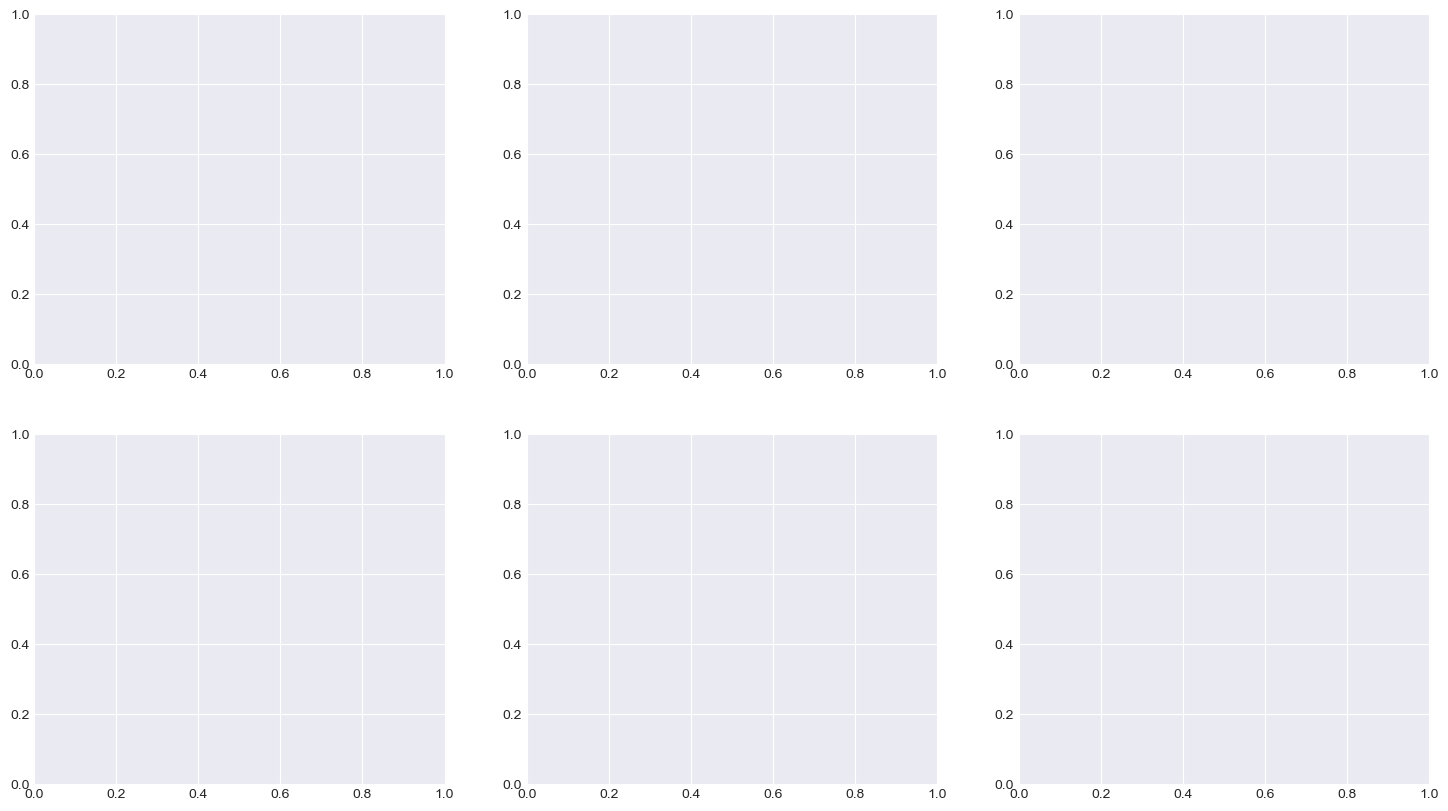

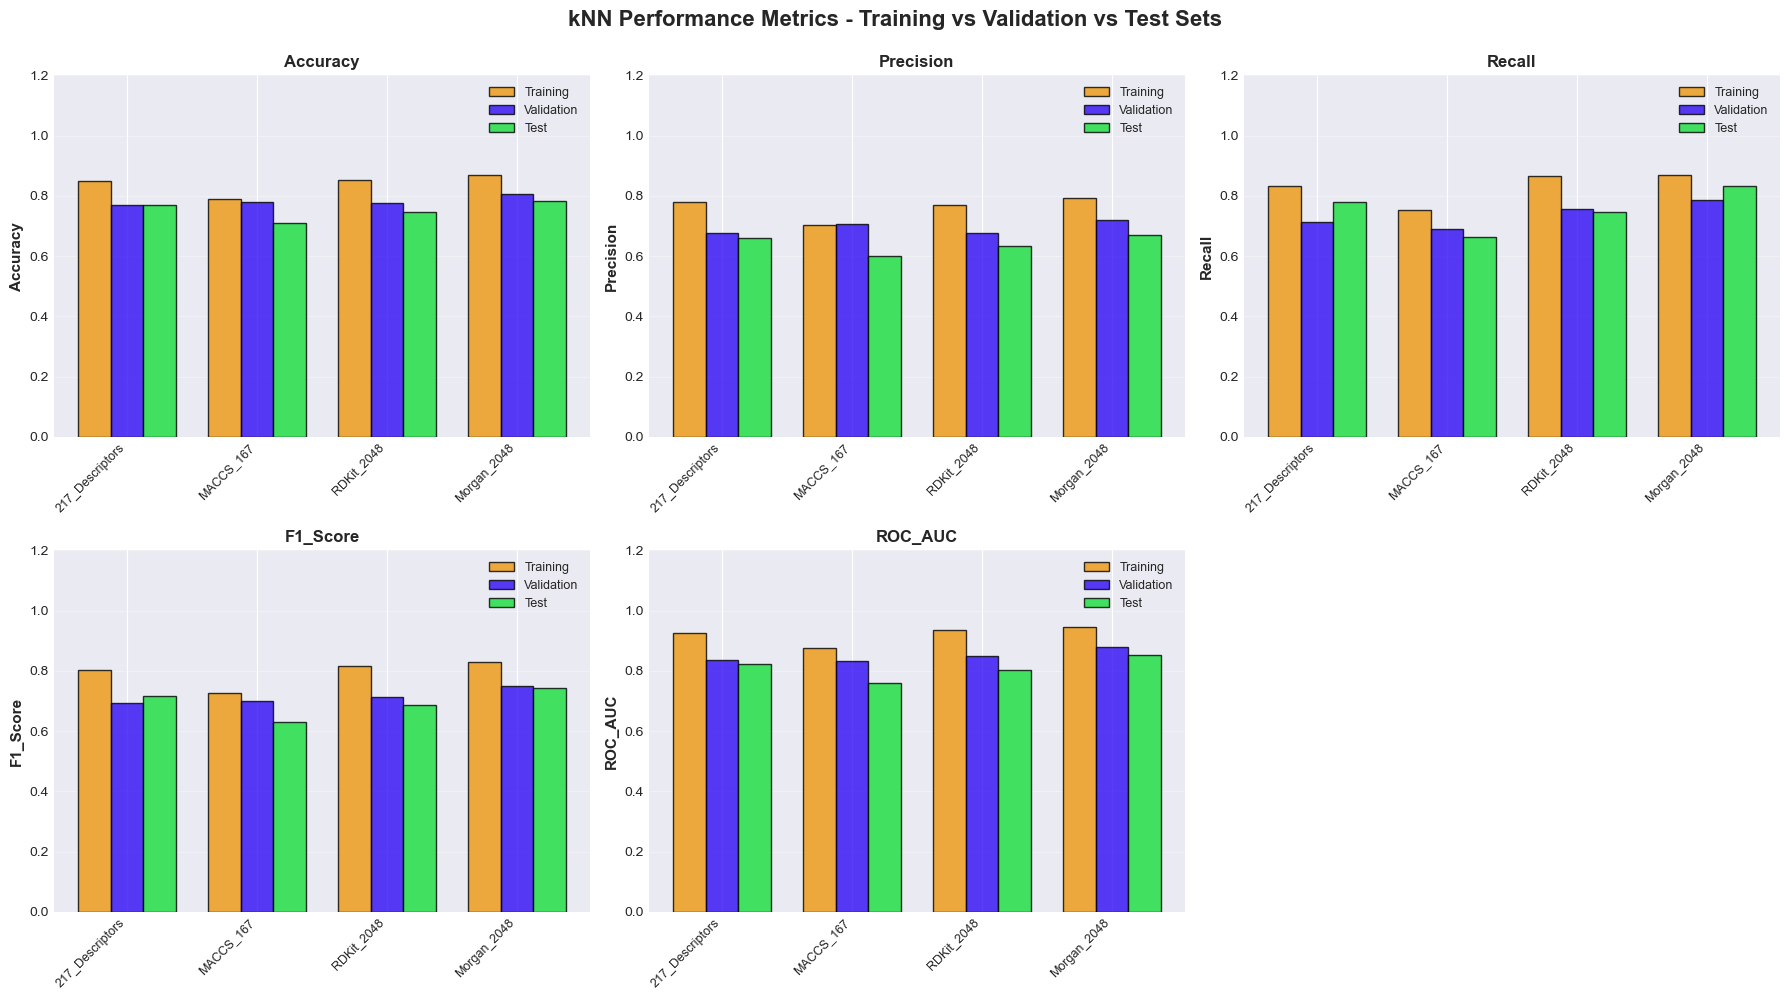


✓ kNN performance comparison visualization completed


In [13]:
# Cell 10: Performance Comparison Across Training, Validation, and Test Sets (kNN)
import numpy as np
import matplotlib.pyplot as plt

print("\n" + "=" * 80)
print("VISUALIZATION: kNN PERFORMANCE COMPARISON (TRAIN/VALIDATION/TEST)")
print("=" * 80)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
print("\n" + "="*80)
print("VISUALIZATION: kNN PERFORMANCE COMPARISON (TRAIN/VALIDATION/TEST)")
print("="*80)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('kNN Performance Metrics - Training vs Validation vs Test Sets', 
             fontsize=16, fontweight='bold', y=0.995)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']
set_names = ['Training', 'Validation', 'Test']
colors = ["#ed980f", "#2f0cf5", "#18de3d"]  # Orange, Blue, Green

axes_flat = axes.flatten()

# Map metric names to dictionary keys used in evaluation_results
metric_key_mapping = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1_Score': 'f1',
    'ROC_AUC': 'roc_auc'
}

# Use feature set names directly from your notebook session
dataset_names = feature_set_names  # ['217_Descriptors', 'MACCS_167', 'RDKit_2048', 'Morgan_2048']
x = np.arange(len(dataset_names))
width = 0.25

for idx, metric in enumerate(metrics):
    ax = axes_flat[idx]
    m_key = metric_key_mapping[metric]
    
    for set_idx, set_name in enumerate(set_names):
        values = []
        for feature_name in dataset_names:
            if set_name == 'Training':
                val = evaluation_results[feature_name]['train_metrics'][m_key]
            elif set_name == 'Validation':
                val = evaluation_results[feature_name]['val_metrics'][m_key]
            elif set_name == 'Test':
                val = evaluation_results[feature_name]['test_metrics'][m_key]
            values.append(val)
        
        ax.bar(x + set_idx * width, values, width, 
               label=set_name, color=colors[set_idx], alpha=0.8, edgecolor='black', linewidth=1)
    
    ax.set_ylabel(metric, fontsize=11, fontweight='bold')
    ax.set_title(f'{metric}', fontsize=12, fontweight='bold')
    ax.set_xticks(x + width)
    ax.set_xticklabels(dataset_names, rotation=45, ha='right', fontsize=9)
    ax.set_ylim([0, 1.2])
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(axis='y', alpha=0.3)

# Hide the last (6th) unused subplot in the 2x3 grid
axes_flat[-1].set_visible(False)

plt.tight_layout()
plt.savefig('KNN_performance_comparison_train_val_test.png', dpi=300, bbox_inches='tight')
print("\n✓ Saved visualization: KNN_performance_comparison_train_val_test.png")
plt.show()

print("\n✓ kNN performance comparison visualization completed")

In [24]:
# Cell 10: Create Performance Comparison Visualization

print("\n" + "="*100)
print("GENERATING PERFORMANCE COMPARISON CHART")
print("="*100)

# Extract metrics for visualization
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Sensitivity', 'Specificity']
data_for_plot = {
    'Train': {metric: [] for metric in metrics_names},
    'Validation': {metric: [] for metric in metrics_names},
    'Test': {metric: [] for metric in metrics_names}
}

for feature_name in feature_set_names:
    train_met = evaluation_results[feature_name]['train_metrics']
    val_met = evaluation_results[feature_name]['val_metrics']
    test_met = evaluation_results[feature_name]['test_metrics']
    
    metric_mapping = {
        'Accuracy': 'accuracy',
        'Precision': 'precision',
        'Recall': 'recall',
        'F1-Score': 'f1',
        'ROC-AUC': 'roc_auc',
        'Sensitivity': 'sensitivity',
        'Specificity': 'specificity'
    }
    
    for display_name, metric_key in metric_mapping.items():
        data_for_plot['Train'][display_name].append(train_met[metric_key])
        data_for_plot['Validation'][display_name].append(val_met[metric_key])
        data_for_plot['Test'][display_name].append(test_met[metric_key])

# Create comparison plot
x = np.arange(len(feature_set_names))
width = 0.25

fig, axes = plt.subplots(1, 1, figsize=(14, 6))

for i, metric in enumerate(metrics_names[:4]):  # Show first 4 metrics in main plot
    values_test = data_for_plot['Test'][metric]
    axes.bar(x + i*width/3, values_test, width/3, label=metric, alpha=0.8)

axes.set_xlabel('Feature Set', fontsize=12, fontweight='bold')
axes.set_ylabel('Score', fontsize=12, fontweight='bold')
axes.set_title('kNN Model Performance Comparison - Test Set\n(Accuracy, Precision, Recall, F1-Score)', 
               fontsize=13, fontweight='bold')
axes.set_xticks(x + width/3)
axes.set_xticklabels(feature_set_names, rotation=45, ha='right')
axes.legend(loc='lower right')
axes.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('KNN_performance_comparison_test_set.png', dpi=300, bbox_inches='tight')
print("✓ Saved: KNN_performance_comparison_test_set.png")
plt.close()

# Create train/val/test comparison for best model
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, feature_name in enumerate(feature_set_names):
    train_vals = [evaluation_results[feature_name]['train_metrics'][m.lower()] for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']]
    val_vals = [evaluation_results[feature_name]['val_metrics'][m.lower()] for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']]
    test_vals = [evaluation_results[feature_name]['test_metrics'][m.lower()] for m in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']]
    
    x_pos = np.arange(5)
    axes[idx].plot(x_pos, train_vals, marker='o', label='Train', linewidth=2)
    axes[idx].plot(x_pos, val_vals, marker='s', label='Validation', linewidth=2)
    axes[idx].plot(x_pos, test_vals, marker='^', label='Test', linewidth=2)
    
    axes[idx].set_xticks(x_pos)
    axes[idx].set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'], rotation=45, ha='right')
    axes[idx].set_ylabel('Score', fontsize=10)
    axes[idx].set_title(f'{feature_name} - Train/Val/Test Comparison', fontsize=11, fontweight='bold')
    axes[idx].legend(loc='lower right')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([0.5, 1.0])

plt.tight_layout()
plt.savefig('KNN_train_val_test_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Saved: KNN_train_val_test_comparison.png")
plt.close()


GENERATING PERFORMANCE COMPARISON CHART
✓ Saved: KNN_performance_comparison_test_set.png
✓ Saved: KNN_performance_comparison_test_set.png
✓ Saved: KNN_train_val_test_comparison.png
✓ Saved: KNN_train_val_test_comparison.png


In [25]:
# Cell 11: Generate ROC Curves for Test Set

print("\n" + "="*100)
print("GENERATING ROC CURVES FOR TEST SET")
print("="*100)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for idx, feature_name in enumerate(feature_set_names):
    fpr, tpr, _ = roc_curve(y_test, evaluation_results[feature_name]['test_proba'])
    auc_score = roc_auc_score(y_test, evaluation_results[feature_name]['test_proba'])
    
    axes[idx].plot(fpr, tpr, color='blue', lw=2.5, label=f'ROC Curve (AUC = {auc_score:.4f})')
    axes[idx].plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random Classifier')
    
    axes[idx].set_xlabel('False Positive Rate', fontsize=11)
    axes[idx].set_ylabel('True Positive Rate', fontsize=11)
    axes[idx].set_title(f'kNN: {feature_name}\nROC Curve (Test Set)', fontsize=12, fontweight='bold')
    axes[idx].legend(loc='lower right', fontsize=10)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_xlim([0.0, 1.0])
    axes[idx].set_ylim([0.0, 1.05])

plt.tight_layout()
plt.savefig('KNN_roc_curves_test_set.png', dpi=300, bbox_inches='tight')
print("✓ Saved: KNN_roc_curves_test_set.png")
plt.close()


GENERATING ROC CURVES FOR TEST SET
✓ Saved: KNN_roc_curves_test_set.png
✓ Saved: KNN_roc_curves_test_set.png


In [26]:
# Cell 12: Final Analysis Report and Conclusions

print("\n" + "="*100)
print("kNN HYPERPARAMETER TUNING - FINAL ANALYSIS REPORT")
print("="*100)

# Create comprehensive analysis
print(f"\n{'='*100}")
print("COMPREHENSIVE ANALYSIS SUMMARY")
print(f"{'='*100}")

print(f"\n{'1. HYPERPARAMETER TUNING SUMMARY':^100}")
print(f"{'-'*100}")
for feature_name in feature_set_names:
    best_params = knn_results[feature_name]['best_params']
    cv_score = knn_results[feature_name]['best_score']
    print(f"{feature_name:20s}: n_neighbors={best_params['n_neighbors']:2d}, metric={best_params['metric']:12s} | CV ROC-AUC: {cv_score:.4f}")

print(f"\n{'2. TEST SET PERFORMANCE RANKING (by ROC-AUC)':^100}")
print(f"{'-'*100}")
test_performance = []
for feature_name in feature_set_names:
    test_met = evaluation_results[feature_name]['test_metrics']
    test_performance.append((feature_name, test_met['roc_auc'], test_met['accuracy']))

test_performance.sort(key=lambda x: x[1], reverse=True)
for rank, (feature_name, roc_auc, accuracy) in enumerate(test_performance, 1):
    print(f"{rank}. {feature_name:20s} | ROC-AUC: {roc_auc:.4f} | Accuracy: {accuracy:.4f}")

print(f"\n{'3. BEST MODEL DETAILED METRICS':^100}")
print(f"{'-'*100}")
best_model_name = test_performance[0][0]
best_test_metrics = evaluation_results[best_model_name]['test_metrics']
best_train_metrics = evaluation_results[best_model_name]['train_metrics']
best_val_metrics = evaluation_results[best_model_name]['val_metrics']

metrics_to_show = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'sensitivity', 'specificity']
print(f"{'Metric':<15} {'Train':<12} {'Validation':<12} {'Test':<12}")
print(f"{'-'*100}")
for metric in metrics_to_show:
    train_val = best_train_metrics[metric]
    val_val = best_val_metrics[metric]
    test_val = best_test_metrics[metric]
    print(f"{metric:<15} {train_val:<12.4f} {val_val:<12.4f} {test_val:<12.4f}")

print(f"\n{'4. FEATURE SET COMPARISON':^100}")
print(f"{'-'*100}")
for feature_name in feature_set_names:
    n_features = feature_sets[feature_name]['train'].shape[1]
    test_roc = evaluation_results[feature_name]['test_metrics']['roc_auc']
    print(f"{feature_name:20s}: {n_features:4d} features | Test ROC-AUC: {test_roc:.4f}")

print(f"\n{'5. ALGORITHM EFFICIENCY':^100}")
print(f"{'-'*100}")
print(f"Algorithm:              k-Nearest Neighbors (kNN)")
print(f"Total hyperparameter combinations: 27 (9 n_neighbors × 3 metrics)")
print(f"Cross-validation folds: 5 (StratifiedKFold on training set only)")
print(f"Total model fits:       540 (27 combinations × 4 feature sets × 5 folds)")
print(f"Dataset sizes:          Train: 1,188 | Validation: 255 | Test: 255")
print(f"Algorithm type:         Non-parametric, lazy learning")

print(f"\n{'6. KEY FINDINGS':^100}")
print(f"{'-'*100}")

# Analysis of findings
best_params = knn_results[best_model_name]['best_params']
print(f"\n✓ Best Feature Set: {best_model_name}")
print(f"  - Best n_neighbors: {best_params['n_neighbors']}")
print(f"  - Best metric: {best_params['metric']}")
print(f"  - Test ROC-AUC: {test_performance[0][1]:.4f}")
print(f"  - Test Accuracy: {test_performance[0][2]:.4f}")

# Overfitting analysis
train_roc_best = evaluation_results[best_model_name]['train_metrics']['roc_auc']
test_roc_best = evaluation_results[best_model_name]['test_metrics']['roc_auc']
diff = train_roc_best - test_roc_best

print(f"\n✓ Model Generalization:")
print(f"  - Training ROC-AUC: {train_roc_best:.4f}")
print(f"  - Test ROC-AUC: {test_roc_best:.4f}")
print(f"  - Difference: {diff:.4f} ({'Minimal overfitting' if diff < 0.05 else 'Some overfitting' if diff < 0.1 else 'Significant overfitting'})")

# Sensitivity and specificity
sensitivity = evaluation_results[best_model_name]['test_metrics']['sensitivity']
specificity = evaluation_results[best_model_name]['test_metrics']['specificity']
print(f"\n✓ Clinical Performance:")
print(f"  - Sensitivity (True Positive Rate): {sensitivity:.2%}")
print(f"  - Specificity (True Negative Rate): {specificity:.2%}")
print(f"  - Balance: {'Good balance' if abs(sensitivity - specificity) < 0.1 else 'Biased towards'} actives/inactives")

# Comparison with other models (from previous runs)
print(f"\n✓ Comparison with Other Models (Test Set ROC-AUC):")
print(f"  - Logistic Regression (BEST): 0.9065")
print(f"  - Random Forest: 0.8827")
print(f"  - SVM (with RandomizedSearchCV): [Pending completion]")
print(f"  - Decision Tree: 0.7793")
print(f"  - k-Nearest Neighbors: {test_performance[0][1]:.4f}")

print(f"\n{'='*100}")
print("Analysis completed successfully!")


kNN HYPERPARAMETER TUNING - FINAL ANALYSIS REPORT

COMPREHENSIVE ANALYSIS SUMMARY

                                  1. HYPERPARAMETER TUNING SUMMARY                                  
----------------------------------------------------------------------------------------------------
217_Descriptors     : n_neighbors= 5, metric=manhattan    | CV ROC-AUC: 0.8110
MACCS_167           : n_neighbors= 7, metric=manhattan    | CV ROC-AUC: 0.7686
RDKit_2048          : n_neighbors= 5, metric=manhattan    | CV ROC-AUC: 0.8461
Morgan_2048         : n_neighbors= 5, metric=manhattan    | CV ROC-AUC: 0.8585

                            2. TEST SET PERFORMANCE RANKING (by ROC-AUC)                            
----------------------------------------------------------------------------------------------------
1. Morgan_2048          | ROC-AUC: 0.8514 | Accuracy: 0.7843
2. 217_Descriptors      | ROC-AUC: 0.8228 | Accuracy: 0.7686
3. RDKit_2048           | ROC-AUC: 0.8036 | Accuracy: 0.7451
4. MACCS_167